# Notebook 04 — Pose-graph SLAM, loop closures and false closures

Companion to [Lecture 4](../04_slam_and_localization.md) (§1–§2). We optimise a small 2-D pose graph with
Gauss–Newton (4.1–4.2, Figure 4.1), then see how per-link uncertainty decides whether a false loop closure
is accepted.

In [1]:
import warnings; warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.color': '#e4e3df',
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'

In [2]:
wrap = lambda a: np.arctan2(np.sin(a), np.cos(a))
def between(a, b):       # pose of b in a's frame
    c, s = np.cos(a[2]), np.sin(a[2]); d = b[:2] - a[:2]
    return np.array([c*d[0] + s*d[1], -s*d[0] + c*d[1], wrap(b[2] - a[2])])
def compose(a, d):
    c, s = np.cos(a[2]), np.sin(a[2])
    return np.array([a[0] + c*d[0] - s*d[1], a[1] + s*d[0] + c*d[1], wrap(a[2] + d[2])])

## 1. A two-lap drive around the stadium track, one node every 0.5 m

In [3]:
def track_pose(s):
    s %= 47.57
    if s < 17.5: return np.array([-10.5 + s, 0, 0])
    s -= 17.5
    if s < 2*np.pi: a = -np.pi/2 + s/2; return np.array([7 + 2*np.cos(a), 2 + 2*np.sin(a), a + np.pi/2])
    s -= 2*np.pi
    if s < 17.5: return np.array([7 - s, 4, np.pi])
    s -= 17.5; a = np.pi/2 + s/2; return np.array([-10.5 + 2*np.cos(a), 2 + 2*np.sin(a), a + np.pi/2])
truth = np.array([track_pose(s) for s in np.arange(0, 2*47.57, 0.5)]); n = len(truth)
rng = np.random.default_rng(0)
odom = [between(truth[i], truth[i+1]) + np.array([rng.normal(0, 0.005), rng.normal(0, 0.005), 0.003 + rng.normal(0, 0.002)])
        for i in range(n - 1)]                                     # note the small heading bias
dead = [truth[0]]
for d in odom: dead.append(compose(dead[-1], d))
dead = np.array(dead); print(n, 'nodes; dead-reckoning end error', round(float(np.hypot(*(dead[-1, :2] - truth[-1, :2]))), 2), 'm')

191 nodes; dead-reckoning end error 5.27 m


## 2. Gauss–Newton on the pose graph (§1)
Each edge $(i, j, \mathbf z_{ij}, \Omega_{ij})$ contributes $\mathbf e_{ij}^\top\Omega_{ij}\mathbf e_{ij}$ with
$\mathbf e_{ij} = \mathbf z_{ij} \ominus (\ominus\mathbf x_i \oplus \mathbf x_j)$ (4.1). We use numerical
Jacobians for clarity; the first pose is fixed to remove the gauge freedom.

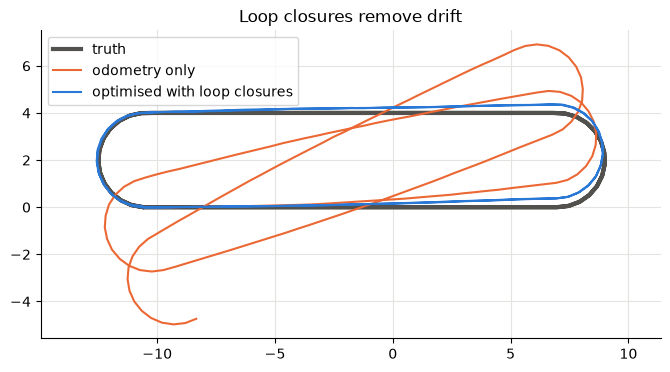

RMS error: odometry 2.503 m, optimised 0.245 m


In [4]:
def optimise(x0, edges, iters=10):
    x = x0.copy()
    for _ in range(iters):
        H = np.zeros((3*n, 3*n)); b = np.zeros(3*n)
        for i, j, z, Om in edges:
            e = between(x[i], x[j]) - z; e[2] = wrap(e[2])
            J = np.zeros((3, 6)); eps = 1e-6
            for k in range(6):
                xp = x.copy(); (xp[i] if k < 3 else xp[j])[k % 3] += eps
                ep = between(xp[i], xp[j]) - z; ep[2] = wrap(ep[2]); J[:, k] = (ep - e)/eps
            idx = np.r_[3*i:3*i+3, 3*j:3*j+3]
            H[np.ix_(idx, idx)] += J.T @ Om @ J; b[idx] += J.T @ Om @ e
        H[:3, :3] += 1e6*np.eye(3)                                   # fix the first pose
        dx = np.linalg.solve(H, -b); x = x + dx.reshape(-1, 3); x[:, 2] = wrap(x[:, 2])
        if np.abs(dx).max() < 1e-6: break
    return x

def link_info(sd_xy, sd_th): return np.diag([1/sd_xy**2, 1/sd_xy**2, 1/sd_th**2])
odom_edges = [(i, i+1, odom[i], link_info(0.005, 0.003)) for i in range(n - 1)]
lap = int(round(47.57/0.5))
closures = [(i, i + lap, between(truth[i], truth[i + lap]) + rng.normal(0, 0.01, 3), link_info(0.02, 0.01))
            for i in range(0, n - lap, 10)]                            # second lap re-sees the first
opt = optimise(dead, odom_edges + closures)
for name, p, c in (('truth', truth, GREY), ('odometry only', dead, ORANGE), ('optimised with loop closures', opt, BLUE)):
    plt.plot(p[:, 0], p[:, 1], color=c, label=name, lw=3 if name == 'truth' else 1.5)
plt.axis('equal'); plt.legend(); plt.title('Loop closures remove drift'); plt.show()
print('RMS error: odometry %.3f m, optimised %.3f m' % (np.sqrt(np.mean(np.sum((dead[:, :2]-truth[:, :2])**2, 1))),
                                                      np.sqrt(np.mean(np.sum((opt[:, :2]-truth[:, :2])**2, 1)))))

## 3. A false closure between look-alike rack bays (§2)
Repeating rack bays make node *i* (lap 1, $x = -7$ m) look identical to node *j* (lap 2, $x = -3.5$ m), and the
matcher proposes "same place". Like SAURCON's aisles, no other closures link these two segments, so the 3.5 m
error can be spread along a whole lap of odometry links. We optimise with the false closure and apply
RTAB-Map's check: reject if any link's residual exceeds 3 of *its claimed* standard deviations.

true separation of the two nodes: [3.43 0.   0.  ]


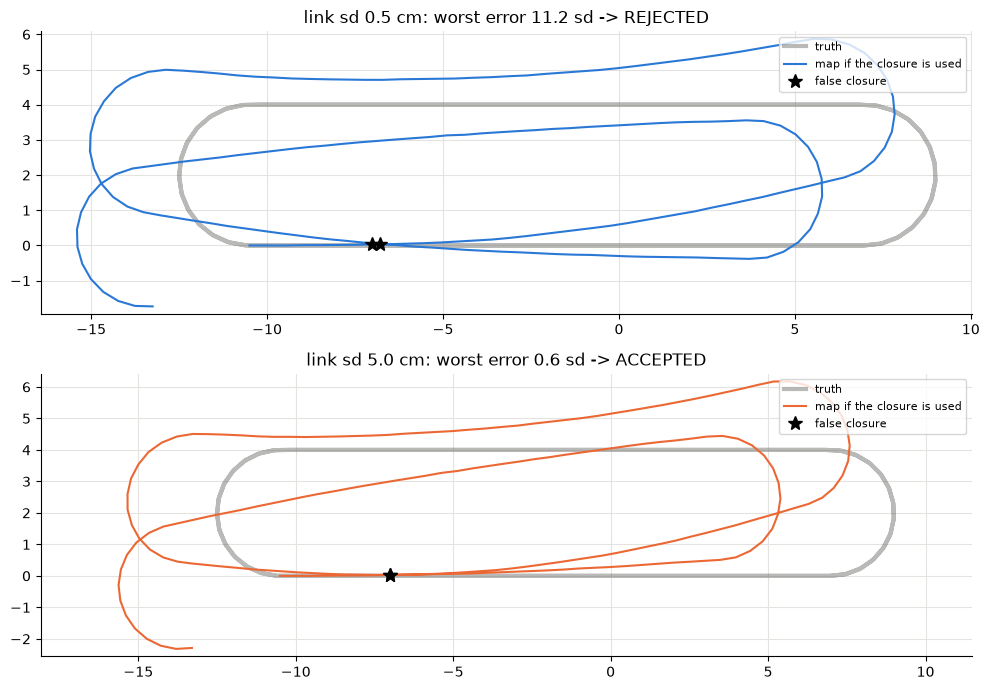

In [5]:
i_f = int(round(3.5/0.5)); j_f = lap + int(round(7.0/0.5))          # x = -7 (lap 1) and x = -3.5 (lap 2)
print('true separation of the two nodes:', np.round(between(truth[i_f], truth[j_f]), 2))
false_z = np.zeros(3)                                                   # the matcher claims: same pose
def check(sd_link):
    edges = [(i, i+1, odom[i], link_info(sd_link, sd_link/2)) for i in range(n - 1)]
    edges.append((i_f, j_f, false_z, link_info(0.02, 0.01)))
    x = optimise(dead, edges)
    def normalised(i, j, z, Om):
        e = between(x[i], x[j]) - z; e[2] = wrap(e[2])
        return np.max(np.abs(e)*np.sqrt(np.diag(Om)))
    return x, max(normalised(*ed) for ed in edges)
fig, axes = plt.subplots(2, 1, figsize=(10, 7))
for ax, sd in zip(axes, (0.005, 0.05)):
    x, worst = check(sd)
    verdict = 'REJECTED' if worst > 3 else 'ACCEPTED'
    ax.plot(truth[:, 0], truth[:, 1], color=GREY, lw=3, alpha=0.4, label='truth')
    ax.plot(x[:, 0], x[:, 1], color=BLUE if worst > 3 else ORANGE, label='map if the closure is used')
    ax.plot(*x[[i_f, j_f], :2].T, 'k*', ms=10, label='false closure')
    ax.set_title(f'link sd {100*sd:.1f} cm: worst error {worst:.1f} sd -> {verdict}'); ax.set_aspect('equal', adjustable='datalim'); ax.legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()

With honest (small) link noise, absorbing the closure would need link errors far beyond their claimed
uncertainty, so it is rejected. With "conservative" large link noise the optimiser shrinks the loop to fit it,
every link stays within 3σ, and the check passes: the map is corrupted, exactly as happened to SAURCON before
the variances were fixed (Lecture 4 §2).

## Problems
Lecture 4's problems **4.1** and **4.2** are done in this notebook.

**N4.1** Find numerically the link standard deviation at which the verdict flips, and compare it with the
analytic threshold of problem 4.2.

**N4.2** Replace the per-link 3σ check with a χ² test on the total cost. Is it more or less sensitive to this
false closure, and why?

**N4.3** Remove the heading bias from the odometry. How many closures are needed for 5 cm RMS?